# PhysioNet motor imagery project

This notebook is a copy of the project Python files, in the order the code fits together, with bar graphs added after the loader.

1. `testPhysioNetPrep.py` loads PhysioNet EEG, filters it, and cuts left-hand and right-hand trials.
2. The bar graphs show those trials for five people whose recordings are already downloaded.
3. `originalPhysioNetPipeline.py` scores Common Spatial Patterns plus linear discriminant analysis on each filter.
4. `improvedPhysioNetPipeline.py` scores the tangent-space models, including real-movement runs added to training.
5. `scaleBenchmark.py` and `testFileImport.py` are the earlier scripts.

The original `.py` files are unchanged. `RUN_FULL_BENCHMARK` scores all 105 subjects and is off, because that download and cross-validation takes a long time. `RUN_LEGACY_SCRIPTS` is off for the same reason. Leave both `False` and run the notebook to produce the bar graphs.

In [4]:
%matplotlib inline

RUN_FULL_BENCHMARK = False
RUN_LEGACY_SCRIPTS = False


## 1. Loader and filters

Copied from `testPhysioNetPrep.py`.

`eegbci.load_data` downloads each subject's EDF recordings, or reuses the local copy. Runs 4, 8, and 12 are imagined left-fist versus right-fist movement. The signal is resampled to 160 Hz, a filter is applied, and each T1 (left) or T2 (right) cue becomes one trial from 0.5 seconds before the cue to 2.0 seconds after. Rest cues are dropped. `X` has shape `(trials, channels, time points)` and `y` is 0 for left, 1 for right.

In [5]:
"""
PhysioNet EEGBCI loader / preprocessor.
Loads motor-imagery data, optionally applies DSP filters, epochs it,
and returns per-subject arrays (X, y), it doesn't use a machine learning pipeline
"""

from joblib import Parallel, delayed
import mne
from mne.datasets import eegbci
from mne.io import read_raw_edf
import numpy as np
import scipy.signal as signal

# Suppress verbose MNE logging outputs to keep the console clean
mne.set_log_level("WARNING")

# Standardized sampling frequency (Hz) so all subjects match in temporal dimension
SFREQ = 160.0  


# DSP FILTERS, works on getting rid of certain frequencies


def apply_notch_filter(raw, freq=60.0, q=30.0):
    """Notch filter to remove 60 Hz power-line interference."""
    out = raw.copy()
    # Design IIR notch filter coefficients (b, a)
    b, a = signal.iirnotch(freq, q, fs=out.info["sfreq"])
    data = out.get_data()
    # Apply zero-phase forward-backward filter across each EEG channel independently
    for i in range(data.shape[0]):
        data[i] = signal.filtfilt(b, a, data[i])
    out._data = data
    return out


def apply_butterworth_bandpass(raw, l_freq=8.0, h_freq=30.0, order=4):
    """Butterworth bandpass filter, it isolates mu + beta frequency bands (8-30 Hz)"""
    out = raw.copy()
    # Design Second-Order Sections (SOS) bandpass filter for numerical stability
    sos = signal.butter(order, [l_freq, h_freq], btype="bandpass",
                        fs=out.info["sfreq"], output="sos")
    data = out.get_data()
    # Apply zero-phase filtering across each channel
    for i in range(data.shape[0]):
        data[i] = signal.sosfiltfilt(sos, data[i])
    out._data = data
    return out


# Maps dictionary to easily select filtering pipelines
FILTER_MODES = {
    "raw": lambda r: r,
    "notch": apply_notch_filter,
    "bandpass": apply_butterworth_bandpass,
    "both": lambda r: apply_notch_filter(apply_butterworth_bandpass(r)),
}



def load_subject(sub, runs, channels, mode="raw", tmin=-0.5, tmax=2.0, baseline=(-0.5, 0)):
    """Returns (X, y) for one subject, or (None, None) if loading fails."""
    try:
        # Download EDF files for the specified subject and experimental runs
        fnames = eegbci.load_data(sub, runs, update_path=False)
        X_runs, y_runs = [], []

        # Process each run separately to prevent edge filter artifacts at boundaries
        for f in fnames:
            raw = read_raw_edf(f, preload=True, verbose=False)
            eegbci.standardize(raw)              # Standardize channel naming conventions (e.g., C3., FC3.)
            raw.resample(SFREQ)                  # Resample to common SFREQ
            raw = FILTER_MODES[mode](raw)        # Apply selected DSP filter mode

            # Extract experimental events and annotations from the raw stream then keeps only motor imagery events 
            # then creates epochs and selects specific channels
            events, event_id = mne.events_from_annotations(raw, verbose=False)
            
            keep = {k: v for k, v in event_id.items() if k in ("T1", "T2")}
            
            epochs = mne.Epochs(raw, events, keep, tmin=tmin, tmax=tmax,
                                baseline=baseline, preload=True, verbose=False)
            
            epochs.pick(channels)

            X_runs.append(epochs.get_data())
            # Convert event IDs to binary labels: T1 -> left (0), T2 -> right (1)
            y_runs.append((epochs.events[:, -1] == keep["T2"]).astype(int))

        return np.concatenate(X_runs), np.concatenate(y_runs)

    except Exception as e:
        print(f"Subject {sub} failed: {e}")
        return None, None



# This part of the code loads the rest of the subjects

# Subjects commonly excluded due to missing files, bad formatting, or unique channel layouts
EXCLUDE = {88, 92, 100, 104}


def load_dataset(subjects=range(1, 110), runs=(4, 8, 12),
                 channels=("C3", "Cz", "C4"), mode="raw",
                 tmin=-0.5, tmax=2.0, baseline=(-0.5, 0), n_jobs=-1):
    """
    Returns dict: {subject_id: (X, y)} for every subject that loaded successfully.
    mode: 'raw' | 'notch' | 'bandpass' | 'both'
    """
    subjects = [s for s in subjects if s not in EXCLUDE]
    
    # Run subject loading tasks concurrently across all CPU cores using joblib
    results = Parallel(n_jobs=n_jobs)(
        delayed(load_subject)(s, list(runs), list(channels), mode, tmin, tmax, baseline)
        for s in subjects
    )
    
    # Package successful results into a dictionary keyed by subject ID
    data = {s: r for s, r in zip(subjects, results) if r[0] is not None}
    print(f"[{mode}] loaded {len(data)}/{len(subjects)} subjects")
    return data


def save_dataset(data, path):
    """Save multi-subject dictionaries into a single compressed .npz archive."""
    arrays = {}
    for s, (X, y) in data.items():
        arrays[f"X_{s}"] = X
        arrays[f"y_{s}"] = y
    np.savez_compressed(path, **arrays)
    print(f"Saved {len(data)} subjects to {path}")

# Plots below keep this name after later sections reuse load_subject.
load_subject_prep = load_subject


This next cell is the bottom of `testPhysioNetPrep.py`. It builds and saves all 109 subjects four times (raw, notch, bandpass, and both). It runs only when `RUN_FULL_BENCHMARK` is `True`.

In [6]:
if RUN_FULL_BENCHMARK:
        # Loop through all filter configurations, process the dataset, and save artifacts
        for mode in ["raw", "notch", "bandpass", "both"]:
            data = load_dataset(subjects=range(1, 110), mode=mode)
            save_dataset(data, f"physionet_{mode}.npz")

            # prints out the shape and label of the first loaded subject
            if data:
                s = next(iter(data))
                X, y = data[s]
                print(f"  subject {s}: X={X.shape}, labels={np.bincount(y)}")
else:
    print('Skipped the full dataset save. Set RUN_FULL_BENCHMARK = True to process all subjects.')


Skipped the full dataset save. Set RUN_FULL_BENCHMARK = True to process all subjects.


## 2. Bar graphs of the loaded trials

These cells call the loader above. Subjects 3, 4, 5, 6, and 8 already have runs 4, 8, and 12 on disk, so this does not start a new PhysioNet download. Blue is the left hand (T1). Orange is the right hand (T2).

In [7]:
import matplotlib.pyplot as plt

PLOT_SUBJECTS = [3, 4, 5, 6, 8]
PLOT_RUNS = [4, 8, 12]
PLOT_CHANNELS = ["C3", "Cz", "C4"]

records = {}
for subject in PLOT_SUBJECTS:
    X, y = load_subject_prep(subject, PLOT_RUNS, PLOT_CHANNELS, mode="raw")
    if X is None:
        print(f"Subject {subject} did not load")
        continue
    records[subject] = (X, y)
    print(
        f"Subject {subject}: X={X.shape}  "
        f"left={(y == 0).sum()}  right={(y == 1).sum()}"
    )

print(f"Loaded {len(records)} subjects")


c:\Users\matth\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Subject 3: X=(45, 3, 401)  left=23  right=22
Subject 4: X=(45, 3, 401)  left=23  right=22
Subject 5: X=(45, 3, 401)  left=21  right=24
Subject 6: X=(45, 3, 401)  left=24  right=21
Subject 8: X=(45, 3, 401)  left=22  right=23
Loaded 5 subjects


### Trials per person

Each pair of bars is one person. These are the trials the classifiers later train and test on.

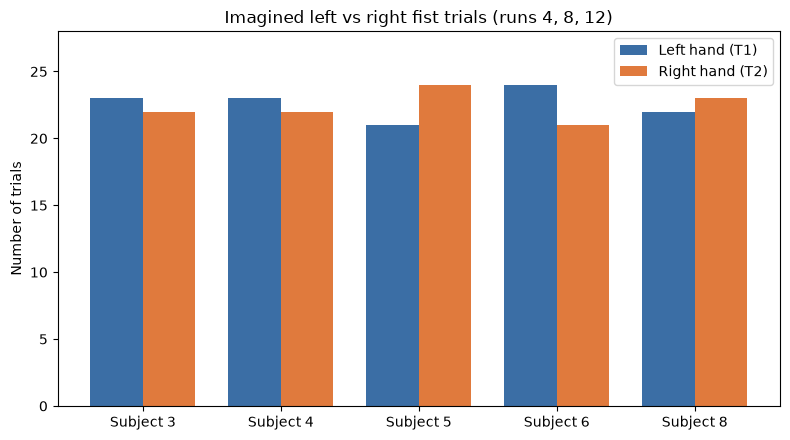

All subjects: left=113  right=112


In [8]:
subjects = list(records)
left_counts = np.array([(records[s][1] == 0).sum() for s in subjects])
right_counts = np.array([(records[s][1] == 1).sum() for s in subjects])

x = np.arange(len(subjects))
width = 0.38

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(x - width / 2, left_counts, width, label="Left hand (T1)", color="#3b6ea5")
ax.bar(x + width / 2, right_counts, width, label="Right hand (T2)", color="#e07a3d")
ax.set_xticks(x, [f"Subject {s}" for s in subjects])
ax.set_ylabel("Number of trials")
ax.set_title("Imagined left vs right fist trials (runs 4, 8, 12)")
ax.legend()
ax.set_ylim(0, max(left_counts.max(), right_counts.max()) + 4)
fig.tight_layout()
fig.savefig("trials_per_subject.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"All subjects: left={left_counts.sum()}  right={right_counts.sum()}")


### Signal size on C3, Cz, and C4

`X` is in volts. The bars are the mean absolute voltage in microvolts, averaged across time and across the trials of that hand. This is the raw baseline, before the notch or bandpass filter.

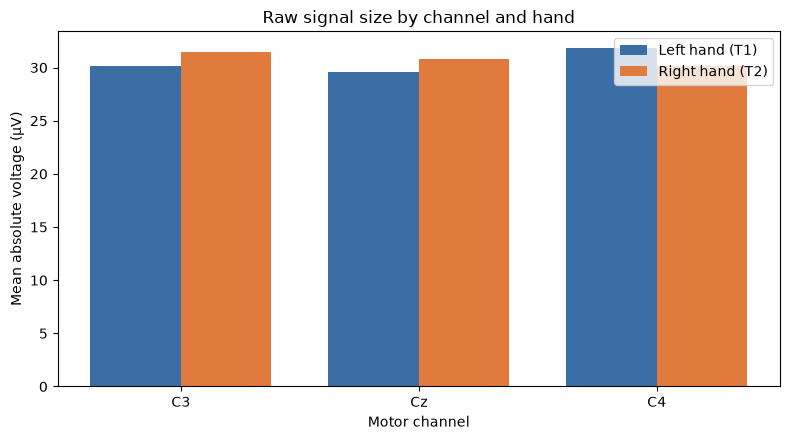

In [9]:
X_all = np.concatenate([records[s][0] for s in subjects], axis=0)
y_all = np.concatenate([records[s][1] for s in subjects], axis=0)

left_uv = np.mean(np.abs(X_all[y_all == 0]), axis=(0, 2)) * 1e6
right_uv = np.mean(np.abs(X_all[y_all == 1]), axis=(0, 2)) * 1e6

x = np.arange(len(PLOT_CHANNELS))
width = 0.38

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(x - width / 2, left_uv, width, label="Left hand (T1)", color="#3b6ea5")
ax.bar(x + width / 2, right_uv, width, label="Right hand (T2)", color="#e07a3d")
ax.set_xticks(x, PLOT_CHANNELS)
ax.set_ylabel("Mean absolute voltage (µV)")
ax.set_xlabel("Motor channel")
ax.set_title("Raw signal size by channel and hand")
ax.legend()
fig.tight_layout()
fig.savefig("amplitude_by_channel.png", dpi=150, bbox_inches="tight")
plt.show()


## 3. Original benchmark

Copied from `originalPhysioNetPipeline.py`.

For each filter state it loads every subject except 88, 92, 100, and 104, then scores Common Spatial Patterns plus linear discriminant analysis with 5-fold cross-validation repeated 3 times. The printed lines are mean accuracy, and how many people reach 70% and 80%.

In [10]:
"""
PhysioNet EEGBCI Baseline Pipeline, it gives the benchmark scores for the testPhysioNetPrep script and doesn't use any improvements
uses 5x3 Repeated Stratified K-Fold
meant to be a direct comparison improvedPhysioNetPipeline.py to see differences in changes with using Python libraries and not using Python libraries
"""
from joblib import Parallel, delayed
import mne
from mne.datasets import eegbci
from mne.io import read_raw_edf
from mne.decoding import CSP
from sklearn.pipeline import Pipeline
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import RepeatedStratifiedKFold
import numpy as np

# Import shared preprocessing components and configurations from preprocessing script
from testPhysioNetPrep import FILTER_MODES, SFREQ, EXCLUDE

# Suppress verbose MNE logs to keep console output clean during parallel loops
mne.set_log_level("WARNING")



SUBJECTS = range(1, 110)
RUNS = [4, 8, 12]                  # Experimental runs corresponding to motor imagery tasks
MOTOR_CHANNELS = ['C3', 'Cz', 'C4'] # Core motor cortex electrode channels
TMIN, TMAX = -0.5, 2.0             # Epoch time window around cue events (seconds)
BASELINE = (-0.5, 0)               # Baseline correction window

# Different signal processing filter states to evaluate and compare
STATES = [
    ("State 0 (Raw Baseline)", "raw"),
    ("State 1 (Notch 60Hz)", "notch"),
    ("State 3 (Butterworth 8-30Hz)", "bandpass"),
    ("State 5 (Combined DSP)", "both"),
]



# Subject Loader, loads three subjects

def load_subject_original(sub, mode):
    """Loads, filters, epochs, and returns (X, y) arrays for a single subject."""
    try:
        fnames = eegbci.load_data(sub, RUNS, update_path=False)
        X_runs, y_runs = [], []

        for f in fnames:
            raw = read_raw_edf(f, preload=True, verbose=False)
            eegbci.standardize(raw)
            raw.resample(SFREQ)
            raw = FILTER_MODES[mode](raw) # Apply the specified DSP filter mode

            events, event_id = mne.events_from_annotations(raw, verbose=False)
            keep = {k: v for k, v in event_id.items() if k in ("T1", "T2")}
            
            epochs = mne.Epochs(
                raw, events, keep, tmin=TMIN, tmax=TMAX,
                baseline=BASELINE, preload=True, verbose=False
            )
            epochs.pick(MOTOR_CHANNELS) # Isolate 3 motor channels

            X_runs.append(epochs.get_data())
            # Convert event IDs to binary labels: T1 -> 0 (left), T2 -> 1 (right)
            y_runs.append((epochs.events[:, -1] == keep["T2"]).astype(int))

        return np.concatenate(X_runs), np.concatenate(y_runs)
    except Exception as e:
        print(f"Subject {sub} failed: {e}")
        return None


# PER-Subject Scoring, gives a score for each subject

def score_subject_original(X, y):
    """Trains a baseline CSP + LDA model and evaluates accuracy via cross-validation."""
    cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=0)
    
    clf = Pipeline([
        ("csp", CSP(n_components=2, reg=None, log=True, norm_trace=False)),
        ("lda", LinearDiscriminantAnalysis()),
    ])

    accs = []
    for tr, te in cv.split(X, y):
        m = clf.fit(X[tr], y[tr])
        accs.append((m.predict(X[te]) == y[te]).mean())

    return np.mean(accs)



# Executes benchmarks and gives benchmark score


The scoring loop is the bottom of `originalPhysioNetPipeline.py`. It runs only when `RUN_FULL_BENCHMARK` is `True`.

In [11]:
subs = [s for s in SUBJECTS if s not in EXCLUDE]
print("--- Running Original Pipeline (Per-Subject Evaluation) ---")

results_summary = {}  

# Loop through each filtering state and run the full benchmarking pipeline
for state_name, mode in STATES:
    loaded = Parallel(n_jobs=-1)(
        delayed(load_subject_original)(s, mode) for s in subs
    )
    data = [r for r in loaded if r is not None]

    # Score all successfully loaded subjects in parallel
    sc = np.array(
        Parallel(n_jobs=-1)(delayed(score_subject_original)(X, y) for X, y in data)
    )

    # Convert scores to percentages for consistency
    sc_pct = sc * 100

    # Calculate benchmarks across the subject population
    resp = sc_pct[sc_pct >= 70.0] 
    resp_mean = float(resp.mean()) if len(resp) > 0 else 0.0
    

    results_summary[state_name] = {
        "mean": float(sc_pct.mean()),
        "std": float(sc_pct.std()),
        "median": float(np.median(sc_pct)),
        "above_70_count": int((sc_pct >= 70.0).sum()),
        "above_80_count": int((sc_pct >= 80.0).sum()),
        "total_subjects": int(len(sc_pct)),
        "responsive_mean": resp_mean
    }

    resp_mean_str = f"{resp_mean:.2f}%" if len(resp) > 0 else "N/A"
    print(
        f"[{state_name}] -> All Mean: {sc_pct.mean():.2f}% (+/- {sc_pct.std():.2f}%) "
        f"| Median: {np.median(sc_pct):.2f}% "
        f"| >=70%: {(sc_pct >= 70.0).sum()}/{len(sc_pct)} (Responsive Mean: {resp_mean_str}) "
        f"| >=80%: {(sc_pct >= 80.0).sum()}/{len(sc_pct)}"
    )

# Dump the dictionary to a JSON file at the end of the run
with open("original_pipeline_results.json", "w") as f:
    json.dump(results_summary, f, indent=4)
print("\nSaved benchmark results to 'original_pipeline_results.json'")

print("\nBenchmark Complete")

--- Running Original Pipeline (Per-Subject Evaluation) ---
[State 0 (Raw Baseline)] -> All Mean: 55.16% (+/- 9.50%) | Median: 54.07% | >=70%: 8/105 (Responsive Mean: 76.94%) | >=80%: 2/105
[State 1 (Notch 60Hz)] -> All Mean: 55.23% (+/- 9.40%) | Median: 53.33% | >=70%: 8/105 (Responsive Mean: 76.76%) | >=80%: 2/105
[State 3 (Butterworth 8-30Hz)] -> All Mean: 58.34% (+/- 11.24%) | Median: 57.04% | >=70%: 15/105 (Responsive Mean: 77.43%) | >=80%: 4/105
[State 5 (Combined DSP)] -> All Mean: 58.34% (+/- 11.24%) | Median: 57.04% | >=70%: 15/105 (Responsive Mean: 77.43%) | >=80%: 4/105

Saved benchmark results to 'original_pipeline_results.json'

Benchmark Complete


Visualization of the code above

Successfully loaded states from JSON: ['State 0 (Raw Baseline)', 'State 1 (Notch 60Hz)', 'State 3 (Butterworth 8-30Hz)', 'State 5 (Combined DSP)']


C:\Users\matth\AppData\Local\Temp\ipykernel_14228\2559604427.py:37: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(loc='upper left', frameon=True)


Saved 'original_pipeline_graph.png'


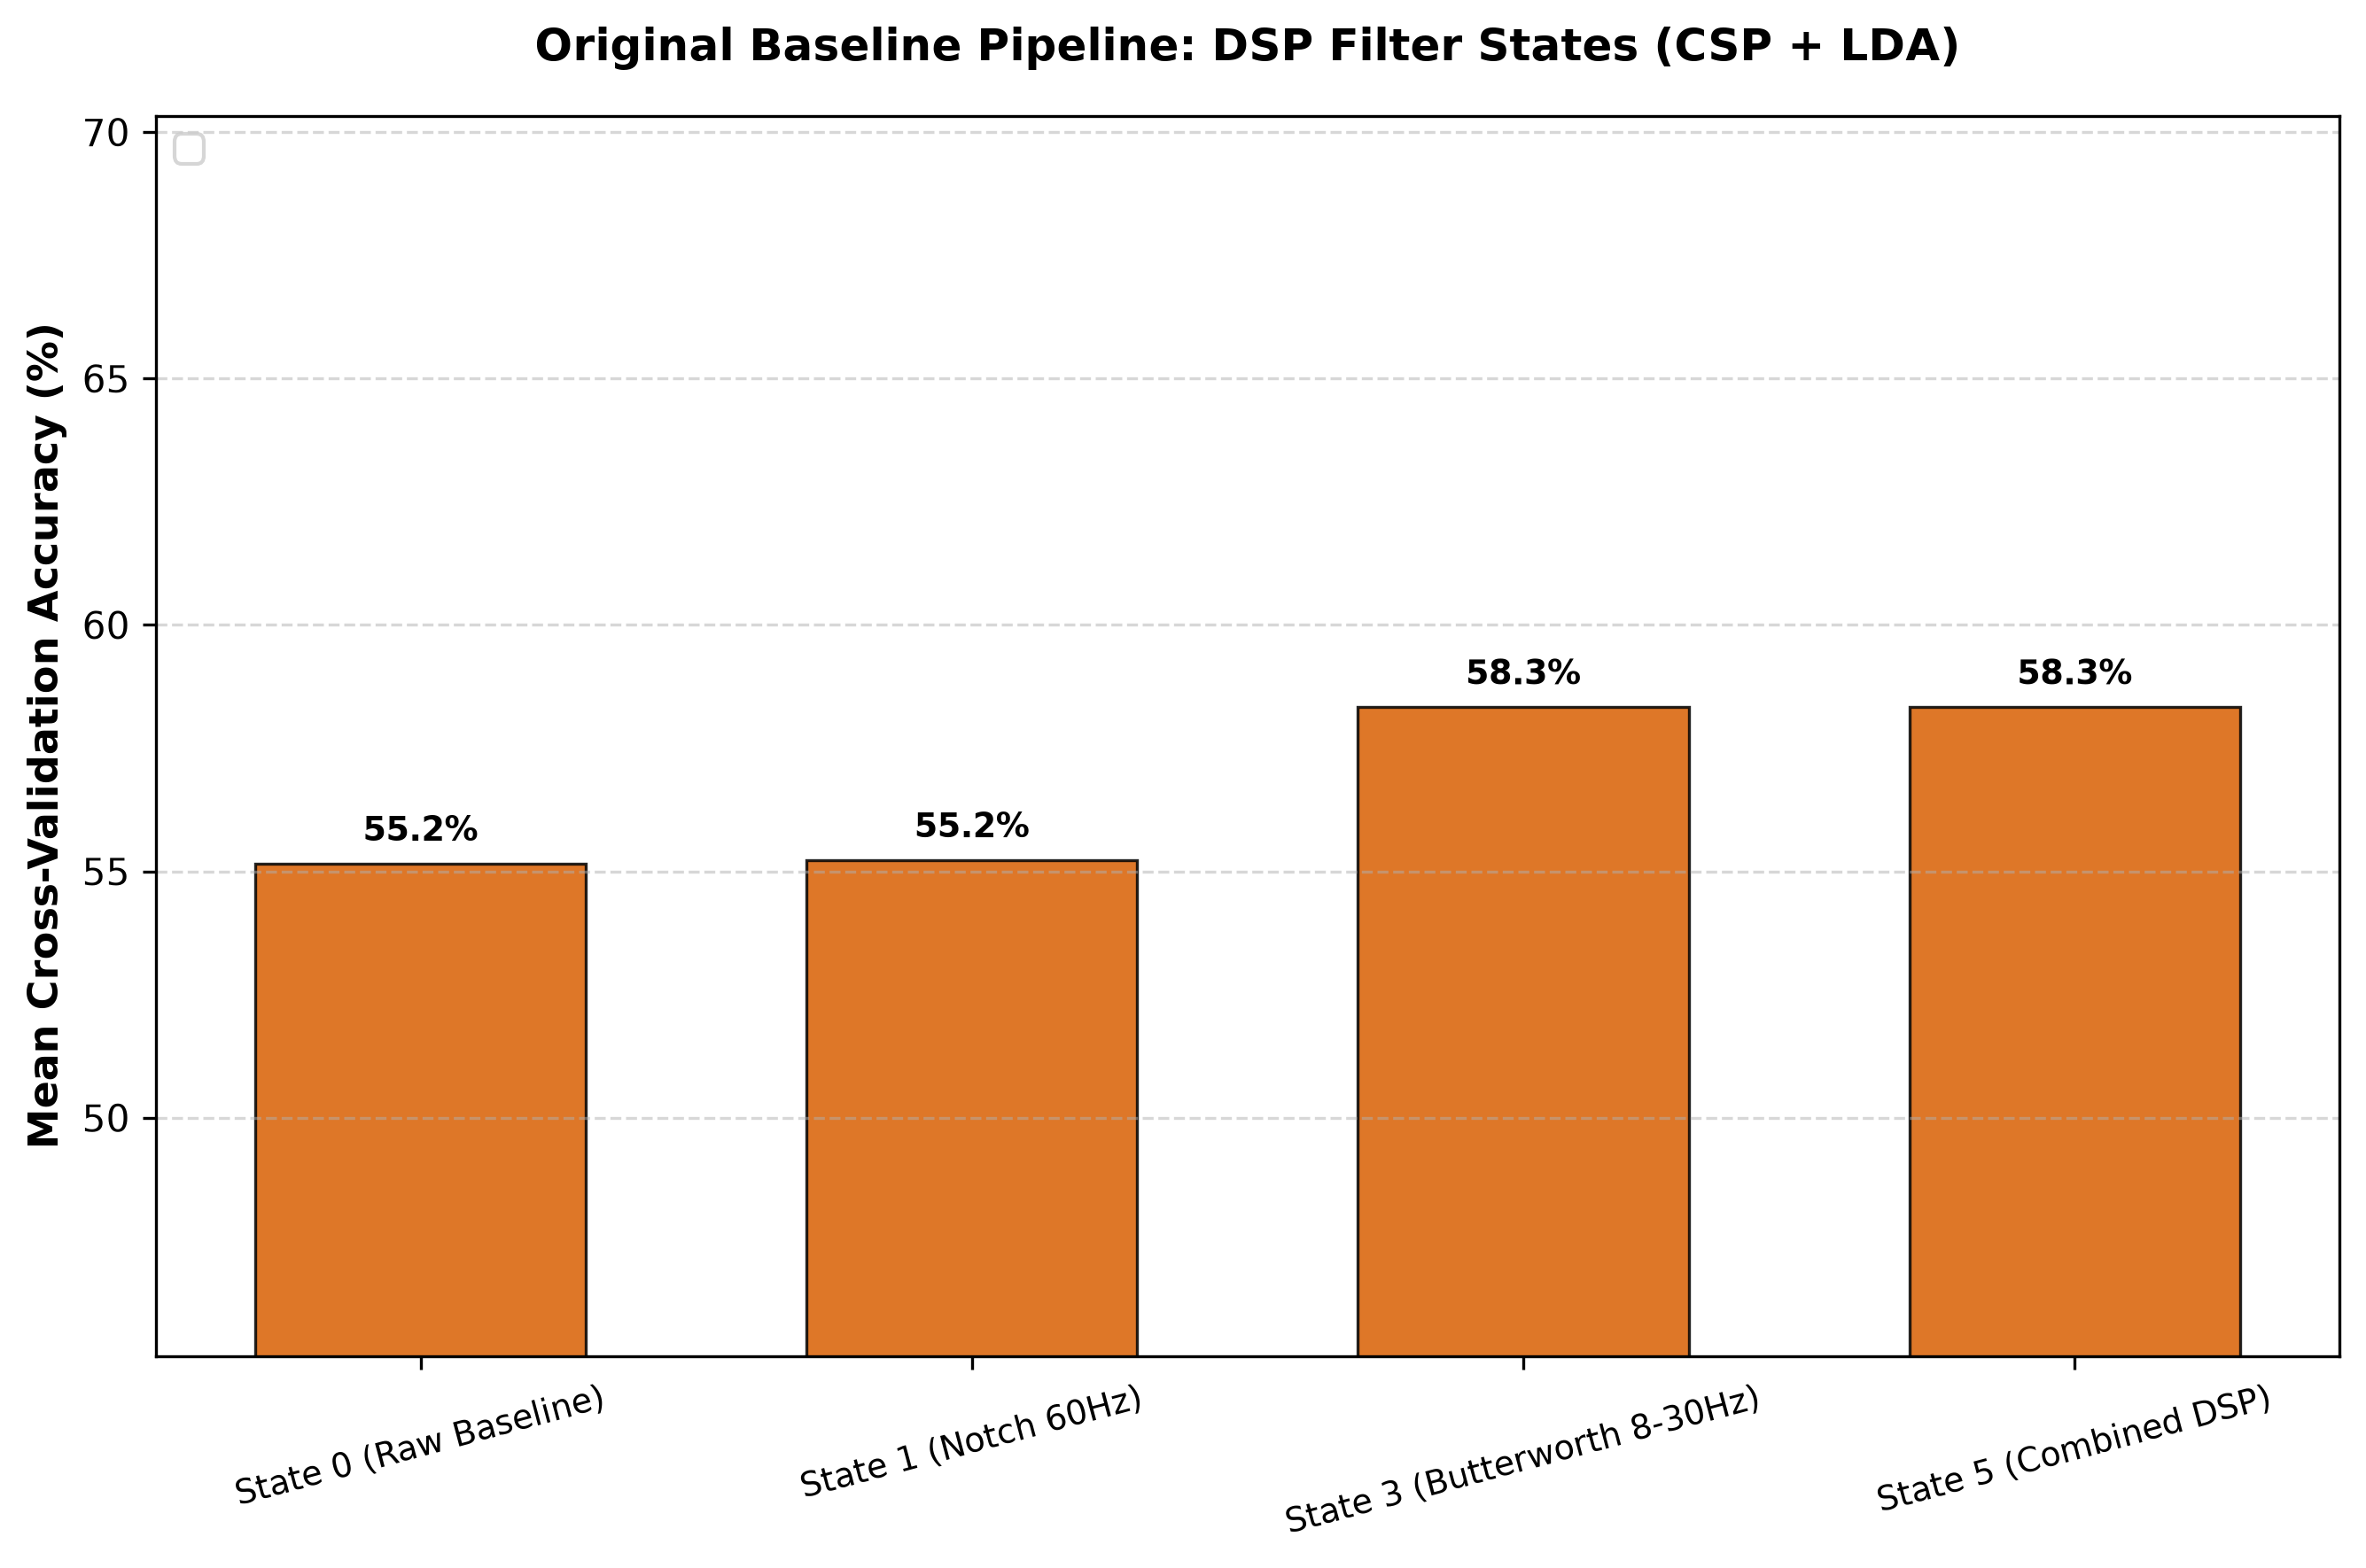

In [12]:
import json
import matplotlib.pyplot as plt

# Load actual metrics saved by originalPhysioNetPipeline.py
with open("original_pipeline_results.json", "r") as f:
    results = json.load(f)

# Automatically grab whatever keys your pipeline script saved
original_states = list(results.keys())
original_accuracies = [results[key]["mean"] for key in original_states]

print("Successfully loaded states from JSON:", original_states)

# Generate the plot
plt.style.use('default')
plt.figure(figsize=(9, 6), dpi=300)

bars = plt.bar(
    original_states, 
    original_accuracies, 
    color='#d95f02', 
    edgecolor='black', 
    linewidth=0.8,
    alpha=0.85,
    width=0.6
)

plt.title('Original Baseline Pipeline: DSP Filter States (CSP + LDA)', fontsize=12, fontweight='bold', pad=15)
plt.ylabel('Mean Cross-Validation Accuracy (%)', fontsize=11, fontweight='semibold')

# Dynamically set y-axis limits based on actual data bounds
ymin = max(0, min(original_accuracies) - 10)
ymax = min(100, max(original_accuracies) + 12)
plt.ylim(ymin, ymax)

plt.xticks(rotation=15, fontsize=9)
plt.legend(loc='upper left', frameon=True)
plt.grid(axis='y', linestyle='--', alpha=0.5)

for bar in bars:
    height = bar.get_height()
    plt.annotate(
        f'{height:.1f}%',
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 4),
        textcoords="offset points",
        ha='center', va='bottom', fontsize=9, fontweight='bold'
    )

plt.tight_layout()
plt.savefig('original_pipeline_graph.png', bbox_inches='tight')
print("Saved 'original_pipeline_graph.png'")
plt.show()

## 4. Improved benchmark

Copied from `improvedPhysioNetPipeline.py`.

This loader uses imagery runs 4, 8, and 12 and real-movement runs 3, 7, and 11. It keeps 15 motor-area channels, bandpass-filters 8–30 Hz, aligns each run, and turns trials into covariance features. Models marked `+exec` add the real-movement trials to training only. The test score is still left versus right on the imagery trials.

In the `.py` file the combined loader is named `load_subject`. Running this section replaces the shared loader of that same name. The bar graphs keep using `load_subject_prep`.

In [13]:
"""
PhysioNet EEGBCI, this code executes per-subject evaluation with:
  Run-level Euclidean Alignment (EA)
  Log-Euclidean Riemannian Tangent Space
  Spatio-Temporal Time-Delay Embedding (delay=4 samples / 25ms)
  Cross-domain augmentation with executed-movement runs (3, 7, 11)

Models evaluated:
  C.       Spatial Tangent Space (8-30 Hz) + Shrinkage LDA
  C+exec.  Spatial Tangent Space + Executed Training Data + Shrinkage LDA
  E.       Spatio-Temporal Tangent Space (delay=4) + Shrinkage LDA
  E+exec.  Spatio-Temporal Tangent Space (delay=4) + Executed Data + Shrinkage LDA
  F+exec.  Spatio-Temporal Tangent Space (delay=4) + Executed Data + LinearSVC
"""

from joblib import Parallel, delayed
import mne
from mne.datasets import eegbci
from mne.io import read_raw_edf
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler
from sklearn.covariance import oas
from sklearn.model_selection import RepeatedStratifiedKFold
import numpy as np


from testPhysioNetPrep import apply_butterworth_bandpass, SFREQ, EXCLUDE

# Suppress verbose MNE logging outputs to keep console clean
mne.set_log_level("WARNING")



SUBJECTS = range(1, 110)       
IMAGERY_RUNS = [4, 8, 12]      
EXEC_RUNS = [3, 7, 11]         
CHANNELS = [                   
    'FC3', 'FC1', 'FCz', 'FC2', 'FC4',
    'C3', 'C1', 'Cz', 'C2', 'C4',
    'CP3', 'CP1', 'CPz', 'CP2', 'CP4'
]
TMIN, TMAX = 0.5, 2.5          
BANDS = [(8, 30)]              
WIDE_IDX = 0



def euclidean_align(X_run):
    """
    Applies Euclidean Alignment to a run's trials and
    re-centers trials so their mean spatial covariance matrix equals the Identity matrix.
    This gets rid of inter-run drift and aligns execution vs. imagery baselines.
    """
    covs = np.array([np.cov(x) for x in X_run])
    R_mean = covs.mean(axis=0)
    w, V = np.linalg.eigh(R_mean)
    # Compute inverse square root of mean covariance matrix
    R_inv_sqrt = (V / np.sqrt(np.maximum(w, 1e-12))) @ V.T
    # Project trial data onto aligned space using Einstein summation
    return np.einsum('ij,njt->nit', R_inv_sqrt, X_run)


def load_runs(sub, runs, align=True):
    """
    Downloads, loads, preprocesses, filters, epochs, and optionally 
    Euclidean-aligns a specified set of runs for a given subject.
    """
    fnames = eegbci.load_data(sub, runs, update_path=False)
    X_runs, y_runs = [], []

    for f in fnames:
        raw = read_raw_edf(f, preload=True, verbose=False)
        eegbci.standardize(raw)
        raw.resample(SFREQ)
        raw.pick(CHANNELS)

        # Extract event annotations 
        events, event_id = mne.events_from_annotations(raw, verbose=False)
        keep = {k: v for k, v in event_id.items() if k in ("T1", "T2")}

        band_data = []
        for lo, hi in BANDS:
            # Apply butterworth bandpass filter for certain frequency band
            r = apply_butterworth_bandpass(raw, lo, hi)
            # Create fixed-length epochs around events
            ep = mne.Epochs(
                r, events, keep, tmin=TMIN, tmax=TMAX,
                baseline=None, preload=True, verbose=False
            )
            # Convert units from Volts to microVolts for numerical stability
            X_band = ep.get_data() * 1e6
            if align:
                X_band = euclidean_align(X_band)
            band_data.append(X_band)

        # Stack frequency bands and collect labels 
        X_runs.append(np.stack(band_data, axis=1).astype(np.float32))
        y_runs.append((ep.events[:, -1] == keep["T2"]).astype(int))

    return np.concatenate(X_runs), np.concatenate(y_runs)


def load_subject(sub):
    """
    Loads both imagery and executed runs for a subject.
    Catches and handles missing files or corrupted subject sessions safely.
    """
    try:
        Xi, yi = load_runs(sub, IMAGERY_RUNS, align=True)
        Xe, ye = load_runs(sub, EXEC_RUNS, align=True)
        return Xi, yi, Xe, ye
    except Exception as e:
        print(f"Subject {sub} failed: {e}")
        return None



class SpatioTemporalTangentSpace(BaseEstimator, TransformerMixin):

    def __init__(self, band_idx=(WIDE_IDX,), delay=4):
        self.band_idx = band_idx
        self.delay = delay

    def _embed_and_cov(self, Xb):
        covs = []
        d = self.delay
        for x in Xb:
            # Time-delay embedding to capture temporal phase dynamics
            if d > 0:
                x_aug = np.vstack([x[:, d:], x[:, :-d]])
            else:
                x_aug = x
            # Compute OAS covariance and normalize by its trace
            c = oas(x_aug.T)[0]
            covs.append(c / np.trace(c))
        return np.stack(covs)

    @staticmethod
    def _log_euclidean_mean(C):
        """Computes the geometric Log-Euclidean mean of a stack of covariance matrices."""
        logs = []
        for c in C:
            w, V = np.linalg.eigh(c)
            logs.append((V * np.log(np.maximum(w, 1e-12))) @ V.T)
        mean_log = np.mean(logs, axis=0)
        w, V = np.linalg.eigh(mean_log)
        return (V * np.exp(w)) @ V.T

    def fit(self, X, y=None):
        """Learns the reference covariance matrix from training data."""
        self.isqrts_ = []
        for b in self.band_idx:
            C = self._embed_and_cov(X[:, b].astype(np.float64))
            ref = self._log_euclidean_mean(C)
            w, V = np.linalg.eigh(ref)
            self.isqrts_.append((V / np.sqrt(np.maximum(w, 1e-12))) @ V.T)
        return self

    def transform(self, X):
        """Projects covariance matrices onto the tangent space and flattens upper triangles."""
        n = X.shape[2] * (2 if self.delay > 0 else 1)
        iu = np.triu_indices(n)
        scale = np.where(iu[0] == iu[1], 1.0, np.sqrt(2.0))

        band_vecs = []
        for b, isqrt in zip(self.band_idx, self.isqrts_):
            C = self._embed_and_cov(X[:, b].astype(np.float64))
            vecs = []
            for c in C:
                # Tangent space mapping relative to reference point
                M = isqrt @ c @ isqrt
                w, V = np.linalg.eigh(M)
                L = (V * np.log(np.maximum(w, 1e-12))) @ V.T
                # Extract upper triangular elements into vector feature representation
                vecs.append(L[iu] * scale)
            band_vecs.append(np.array(vecs))

        return np.concatenate(band_vecs, axis=1)



def make_C_spatial():
    """Creates Pure spatial Riemannian tangent space + feature scaling + Shrinkage LDA."""
    return Pipeline([
        ("ts", SpatioTemporalTangentSpace((WIDE_IDX,), delay=0)),
        ("scale", StandardScaler()),
        ("lda", LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto"))
    ])


def make_E_spatiotemporal():
    """Creates Spatio-temporal tangent space with a delay of 4 along with scaling and Shrinkage LDA."""
    return Pipeline([
        ("ts", SpatioTemporalTangentSpace((WIDE_IDX,), delay=4)),
        ("scale", StandardScaler()),
        ("lda", LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto"))
    ])


def make_F_svm():
    """Creates the same things as Make_E but alos makes a Linear Support Vector Classifer"""
    return Pipeline([
        ("ts", SpatioTemporalTangentSpace((WIDE_IDX,), delay=4)),
        ("scale", StandardScaler()),
        ("svm", LinearSVC(C=0.02, dual="auto", max_iter=3000, random_state=42))
    ])


# Dictionary mapping that calls back to the make functions and whether they are executed or not
MODELS = {
    "C.       Spatial TS (8-30Hz) + shrink LDA":         (make_C_spatial, False),
    "C+exec. Spatial TS + executed training data":        (make_C_spatial, True),
    "E.       Spatio-Temporal TS (delay=4) + shrink LDA": (make_E_spatiotemporal, False),
    "E+exec. Spatio-Temporal TS + exec data + LDA":      (make_E_spatiotemporal, True),
    "F+exec. Spatio-Temporal TS + exec data + SVM":      (make_F_svm, True),
}



def score_subject(Xi, yi, Xe, ye):
    """
    Performs Repeated Stratified K-Fold cross-validation on motor imagery trials
    """
    cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=0)
    splits = list(cv.split(Xi, yi))
    out = {}
    
    for name, (factory, use_exec) in MODELS.items():
        accs = []
        for tr, te in splits:
            Xtr, ytr = Xi[tr], yi[tr]
            # Does Cross-domain augmentation
            if use_exec:
                Xtr = np.concatenate([Xtr, Xe])
                ytr = np.concatenate([ytr, ye])
            # Fit model on training split and evaluate accuracy on test split
            m = factory().fit(Xtr, ytr)
            accs.append((m.predict(Xi[te]) == yi[te]).mean())
        out[name] = np.mean(accs)
    return out


The scoring loop is the bottom of `improvedPhysioNetPipeline.py`.

In [14]:

# Exclude unwanted subjects and load data in parallel across CPU cores
subs = [s for s in SUBJECTS if s not in EXCLUDE]
print("Loading subjects (Euclidean-aligned 8-30Hz imagery + execution runs)")
loaded = Parallel(n_jobs=-1)(delayed(load_subject)(s) for s in subs)
data = [r for r in loaded if r is not None]
print(f"Loaded {len(data)}/{len(subs)} subjects")

print("--- Scoring models per subject ---")
results = Parallel(n_jobs=-1)(delayed(score_subject)(*d) for d in data)

results_summary = {}

# Aggregate and print detailed performance metrics across all subjects
for name in results[0]:
    sc = np.array([r[name] for r in results])
    sc_pct = sc * 100  
    
    resp = sc_pct[sc_pct >= 70.0] # Filter for clinically viable / responsive subjects (>= 70% accuracy)
    resp_mean = float(resp.mean()) if len(resp) > 0 else 0.0

    # Save metrics into the summary dictionary
    results_summary[name] = {
        "mean": float(sc_pct.mean()),
        "std": float(sc_pct.std()),
        "median": float(np.median(sc_pct)),
        "above_70_count": int((sc_pct >= 70.0).sum()),
        "above_80_count": int((sc_pct >= 80.0).sum()),
        "total_subjects": int(len(sc_pct)),
        "responsive_mean": resp_mean
    }

    resp_mean_str = f"{resp_mean:.2f}%" if len(resp) > 0 else "N/A"
    print(
        f"[{name}] -> All Mean: {sc_pct.mean():.2f}% (+/- {sc_pct.std():.2f}%) "
        f"| Median: {np.median(sc_pct):.2f}% "
        f"| >=70%: {(sc_pct >= 70.0).sum()}/{len(sc_pct)} (Responsive Mean: {resp_mean_str}) "
        f"| >=80%: {(sc_pct >= 80.0).sum()}/{len(sc_pct)}"
    )

# Dump the complete dictionary to a JSON file for plotting or reporting
with open("improved_pipeline_results.json", "w") as f:
    json.dump(results_summary, f, indent=4)
print("\nSaved benchmark results to 'improved_pipeline_results.json'")

print("\nBenchmark Complete")


Loading subjects (Euclidean-aligned 8-30Hz imagery + execution runs)
Loaded 105/105 subjects
--- Scoring models per subject ---
[C.       Spatial TS (8-30Hz) + shrink LDA] -> All Mean: 66.91% (+/- 14.59%) | Median: 65.19% | >=70%: 36/105 (Responsive Mean: 83.29%) | >=80%: 21/105
[C+exec. Spatial TS + executed training data] -> All Mean: 67.17% (+/- 15.23%) | Median: 66.67% | >=70%: 41/105 (Responsive Mean: 83.14%) | >=80%: 23/105
[E.       Spatio-Temporal TS (delay=4) + shrink LDA] -> All Mean: 65.86% (+/- 14.55%) | Median: 62.22% | >=70%: 31/105 (Responsive Mean: 84.71%) | >=80%: 20/105
[E+exec. Spatio-Temporal TS + exec data + LDA] -> All Mean: 66.86% (+/- 14.94%) | Median: 63.70% | >=70%: 42/105 (Responsive Mean: 82.40%) | >=80%: 24/105
[F+exec. Spatio-Temporal TS + exec data + SVM] -> All Mean: 65.41% (+/- 14.11%) | Median: 61.48% | >=70%: 35/105 (Responsive Mean: 82.48%) | >=80%: 20/105

Saved benchmark results to 'improved_pipeline_results.json'

Benchmark Complete


Visualization of the improved phyionet pipeline

C:\Users\matth\AppData\Local\Temp\ipykernel_14228\2440379481.py:45: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(loc='upper left', frameon=True)


Saved 'improved_pipeline_graph.png'


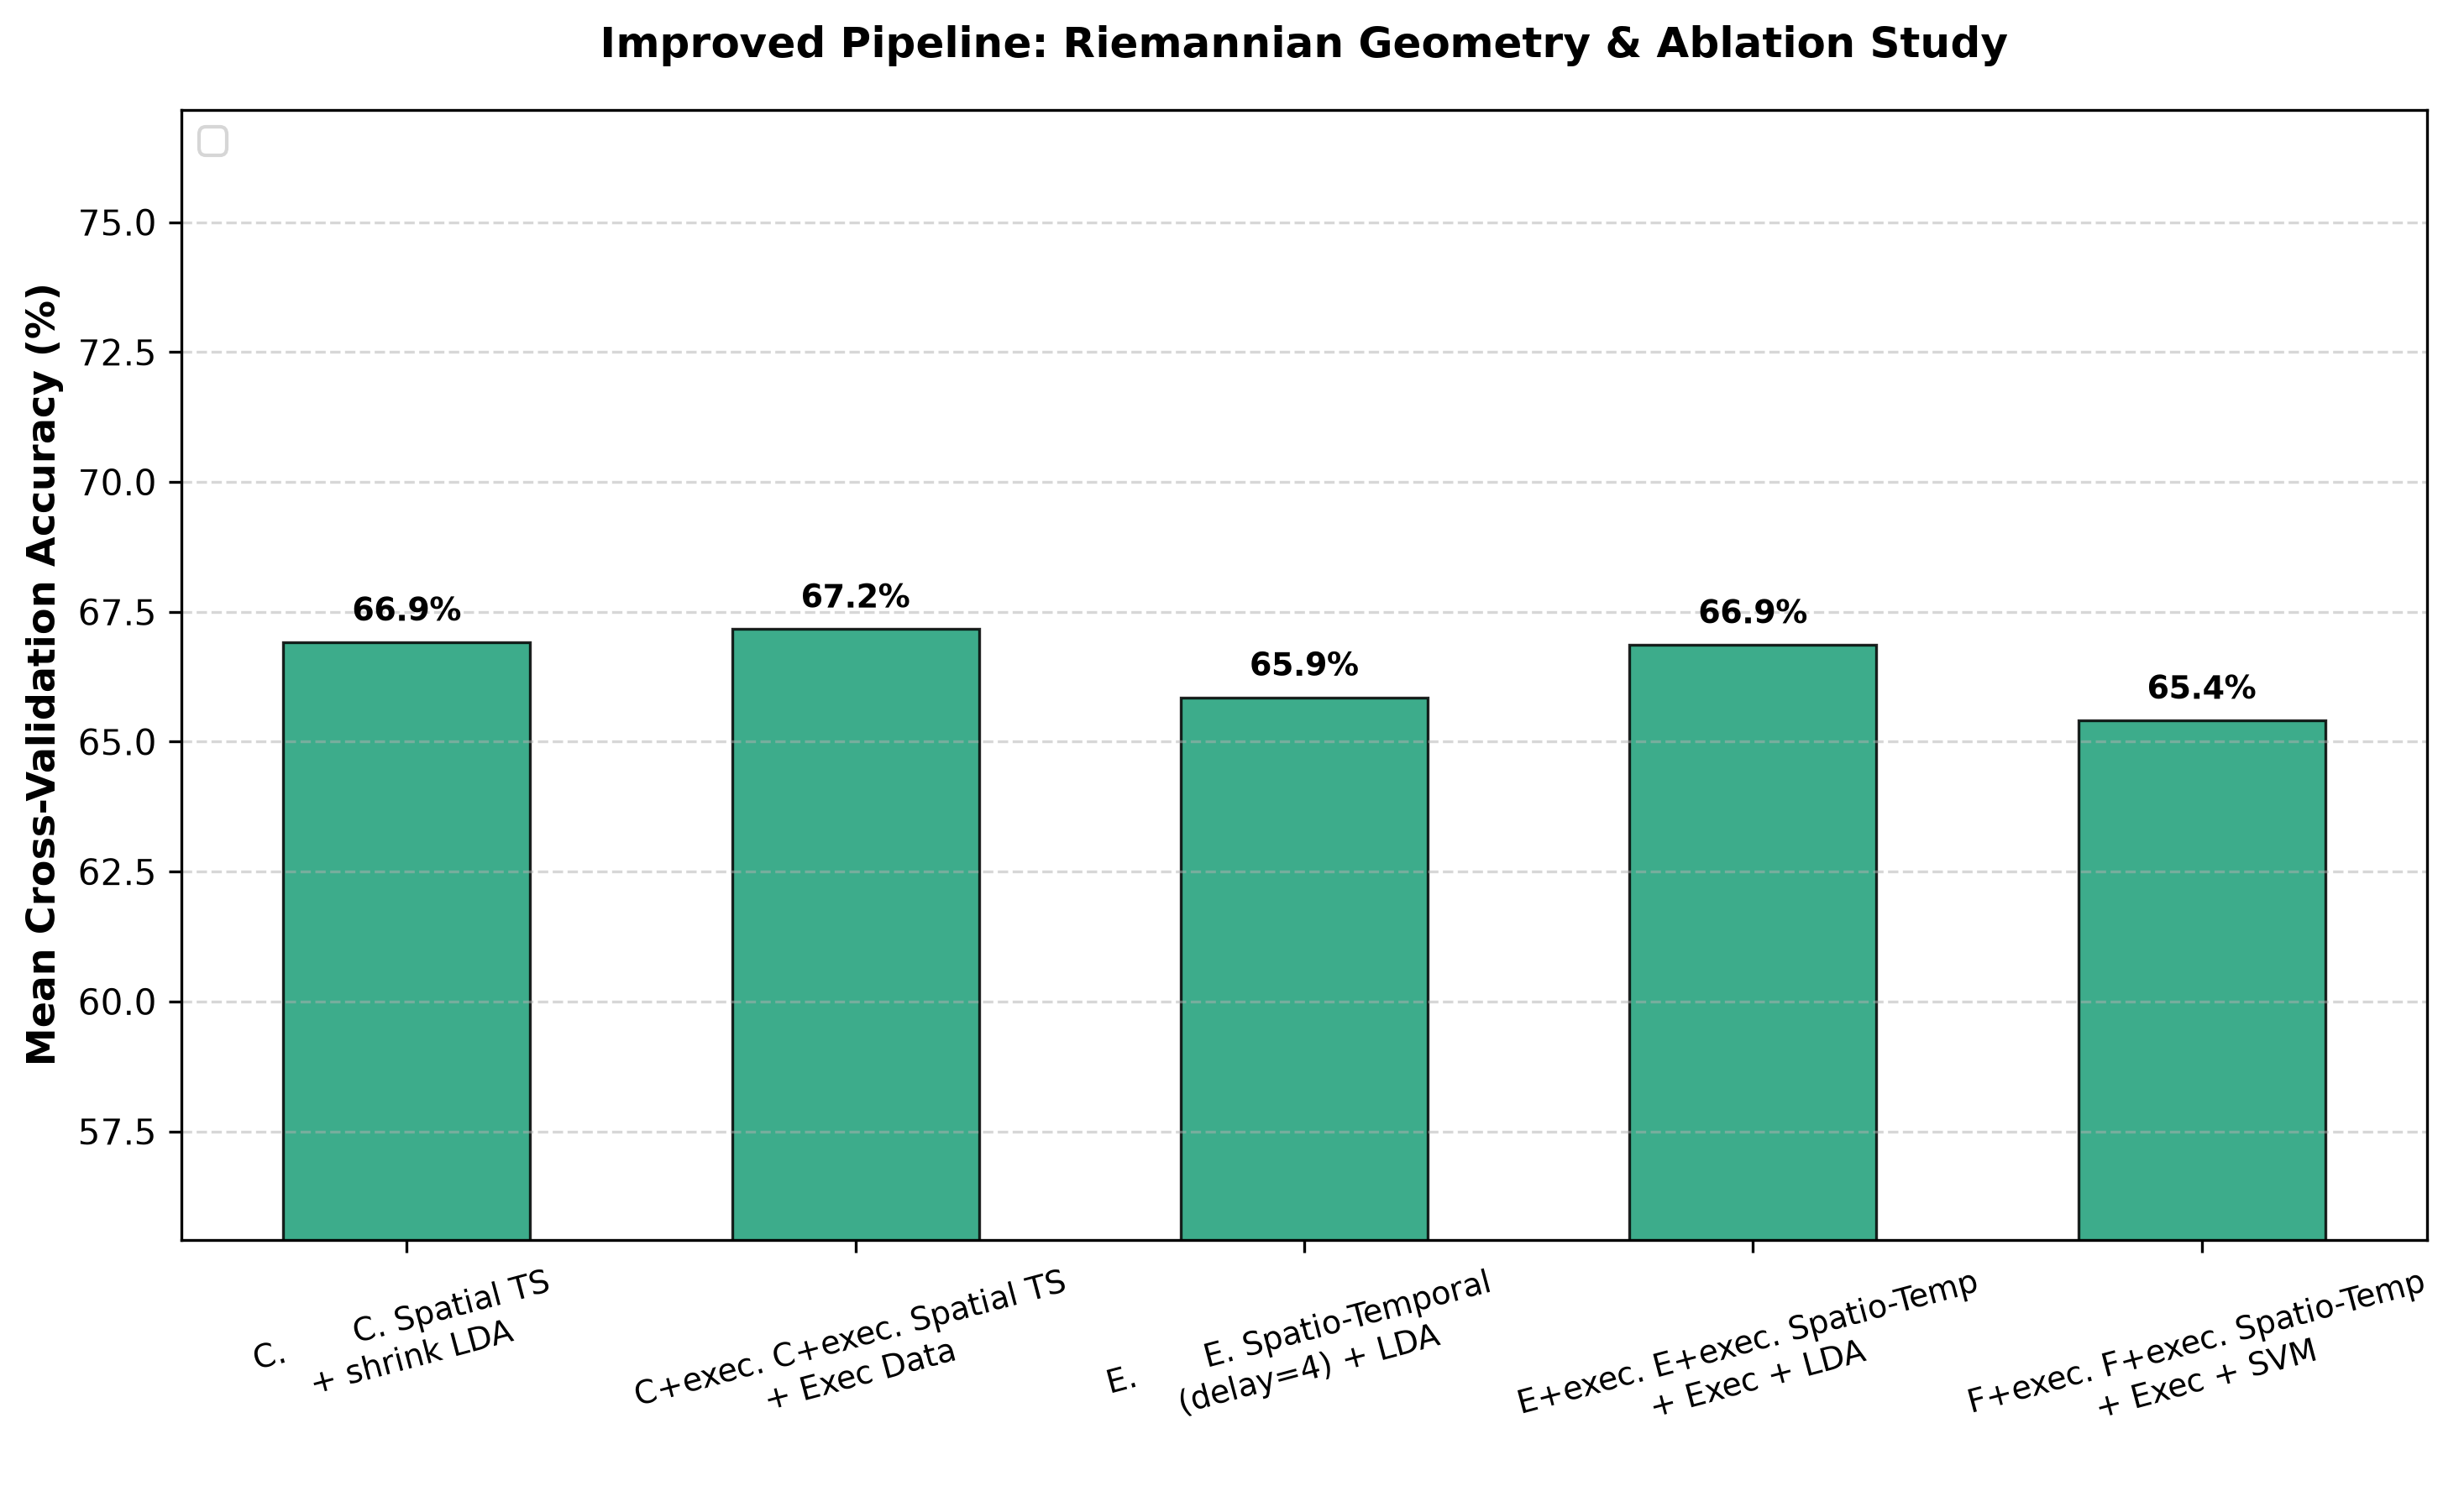

In [15]:
import json
import matplotlib.pyplot as plt

# Load actual metrics saved by improvedPhysioNetPipeline.py
with open("improved_pipeline_results.json", "r") as f:
    results = json.load(f)

# Extract model names and their corresponding mean accuracies
model_names = list(results.keys())
model_accuracies = [results[name]["mean"] for name in model_names]

# Clean up long display labels for the x-axis if needed
clean_labels = [
    name.replace("Spatial TS (8-30Hz) + shrink LDA", "C. Spatial TS\n+ shrink LDA")
        .replace("Spatial TS + executed training data", "C+exec. Spatial TS\n+ Exec Data")
        .replace("Spatio-Temporal TS (delay=4) + shrink LDA", "E. Spatio-Temporal\n(delay=4) + LDA")
        .replace("Spatio-Temporal TS + exec data + LDA", "E+exec. Spatio-Temp\n+ Exec + LDA")
        .replace("Spatio-Temporal TS + exec data + SVM", "F+exec. Spatio-Temp\n+ Exec + SVM")
    for name in model_names
]

# Generate the plot
plt.style.use('default')
plt.figure(figsize=(10, 6), dpi=300)

bars = plt.bar(
    clean_labels, 
    model_accuracies, 
    color='#1b9e77', 
    edgecolor='black', 
    linewidth=0.8,
    alpha=0.85,
    width=0.55
)

plt.title('Improved Pipeline: Riemannian Geometry & Ablation Study', fontsize=12, fontweight='bold', pad=15)
plt.ylabel('Mean Cross-Validation Accuracy (%)', fontsize=11, fontweight='semibold')

# Dynamically set y-axis limits
ymin = max(0, min(model_accuracies) - 10)
ymax = min(100, max(model_accuracies) + 10)
plt.ylim(ymin, ymax)

plt.xticks(rotation=15, fontsize=9)
plt.legend(loc='upper left', frameon=True)
plt.grid(axis='y', linestyle='--', alpha=0.5)

for bar in bars:
    height = bar.get_height()
    plt.annotate(
        f'{height:.1f}%',
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 4),
        textcoords="offset points",
        ha='center', va='bottom', fontsize=9, fontweight='bold'
    )

plt.tight_layout()
plt.savefig('improved_pipeline_graph.png', bbox_inches='tight')
print("Saved 'improved_pipeline_graph.png'")
plt.show()

## 5. Earlier scripts

`scaleBenchmark.py` stacks subjects 1–10 into `X_benchmark_state0.npy` and `y_benchmark.npy`. `testFileImport.py` loads subject 1, run 3, and saves the epoch browser image. Both run only when `RUN_LEGACY_SCRIPTS` is `True`.

In [16]:
if RUN_LEGACY_SCRIPTS:
    import mne
    from mne.datasets import eegbci
    from mne.io import read_raw_edf
    import numpy as np

    """

    The scaled version of `testFileImport.py` contains more data values than the original `testFileImport.py`. 
    However, it currently has a slow runtime, 

    """


    # PhysioNet has 109 subjects this scales it to 10 subjects
    SUBJECTS = list(range(1, 11)) 

    # 4 (left/right fist imagination), 8 (open/close hands), 12 (imagine opening/closing hands)
    RUNS = [4, 8, 12]  
    MOTOR_CHANNELS = ['C3', 'Cz', 'C4']

    all_epochs_data = []
    all_labels = []

    print(f"Starting Full Benchmark Pipeline ({len(SUBJECTS)} Subjects)")

    for subject in SUBJECTS:
        print(f"\nProcessing Subject {subject}/{len(SUBJECTS)}")
    
        try:
            # Download and load all runs for this subject
            raw_fnames = eegbci.load_data(subject, RUNS, update_path=False)
            raws = [read_raw_edf(f, preload=True) for f in raw_fnames]
            raw = mne.concatenate_raws(raws)
        
            # Clean channel names
            raw.rename_channels(lambda x: x.strip('.'))
        
            # Extract events
            events, event_id = mne.events_from_annotations(raw, verbose=False)
        
            # Create epochs (T1 = Left Hand (label 0), T2 = Right Hand (label 1))
            epochs = mne.Epochs(
                raw, 
                events, 
                event_id={'Left_Hand_T1': 2, 'Right_Hand_T2': 3}, 
                tmin=-0.5, 
                tmax=3.0, 
                baseline=(-0.5, 0), 
                preload=True,
                verbose=False
            )
        
            # Isolate motor channels and gets numpy data: shape (n_epochs, n_channels, n_times)
            epochs_motor = epochs.copy().pick(MOTOR_CHANNELS)
            data = epochs_motor.get_data()
        
            # Map MNE event IDs to binary ML labels (0 and 1)
            # T1 (code 2) -> 0, T2 (code 3) -> 1
            labels = epochs.events[:, -1] - 2 
            print("labels", labels)
        
            all_epochs_data.append(data)
            all_labels.append(labels)
            print(f"-> Success! Collected {data.shape[0]} trials for Subject {subject}.")
        
        except Exception as e:
            print(f"-> Error processing Subject {subject}: {e}")

    # Stack everything into Master Matrices for Machine Learning
    if all_epochs_data:
        X = np.concatenate(all_epochs_data, axis=0)
        y = np.concatenate(all_labels, axis=0)
    
        print("MASTER BENCHMARK DATASET READY FOR ML")
        print(f"Total Feature Matrix Shape (X): {X.shape}")  # (N_total_trials, 3 channels, 561 timepoints)
        print(f"Total Labels Shape (y):         {y.shape}")
        print(f"Class Balance:                  Left Hand: {np.sum(y == 0)}, Right Hand: {np.sum(y == 1)}")
    
        # Saves compiled arrays 
        np.save("X_benchmark_state0.npy", X)
        np.save("y_benchmark.npy", y)
        print("Saved master arrays as 'X_benchmark_state0.npy' and 'y_benchmark.npy'!")
    else:
        print("No data was successfully collected.")
else:
    print('Skipped scaleBenchmark.py. Set RUN_LEGACY_SCRIPTS = True to run it.')


Skipped scaleBenchmark.py. Set RUN_LEGACY_SCRIPTS = True to run it.


In [17]:
if RUN_LEGACY_SCRIPTS:
    import mne
    from mne.datasets import eegbci
    from mne.io import read_raw_edf
    import matplotlib.pyplot as plt

    """

    This file demonstrates our baseline data ingestion. 
    It extracts a specific run from the PhysioNet database to show raw EEG brain activity during hand movement tasks, 
    plotting the waveform traces across our target motor channels

    """

    print("Downloads/Loading PhysioNet Data (Subject 1, Run 3)")
    subject = 1
    runs = [3]  
    print("Loading data...")
    raw_fnames = eegbci.load_data(subject, runs)
    raw = read_raw_edf(raw_fnames[0], preload=True)
    raw.rename_channels(lambda x: x.strip('.'))

    print("Extracts Events & Epochs")
    events, event_id = mne.events_from_annotations(raw)


    tmin, tmax = -0.5, 3.0
    epochs = mne.Epochs(
        raw, 
        events, 
        event_id={'Left_Hand_T1': 2, 'Right_Hand_T2': 3}, 
        tmin=tmin, 
        tmax=tmax, 
        baseline=(-0.5, 0), 
        preload=True
    )

    motor_channels = ['C3', 'Cz', 'C4']
    epochs_motor = epochs.copy().pick(motor_channels)

    print("Generating & Saves the Visualization")
    # Generate the plot and capture the figure object
    fig = epochs_motor.plot(picks=motor_channels, title=f"State 0: Raw Motor Channels - Subject {subject}", show=False)

    # Save it directly into your CS506 folder as an image file
    fig.savefig("state0_raw_channels.png", dpi=300, bbox_inches='tight')
    print("The Plot is successfully saved as 'state0_raw_channels.png' in the folder!")

    # Force the interactive window to stay open
    plt.show()
else:
    print('Skipped testFileImport.py. Set RUN_LEGACY_SCRIPTS = True to run it.')


Skipped testFileImport.py. Set RUN_LEGACY_SCRIPTS = True to run it.
